# Period finding with r = 6 on IBM hardware — improved circuit (v3 - ibm_kingston)

The first r = 6 run (302 two-qubit gates, depth 860) lost the signal. This version keeps the same experiment
(9 counting qubits; analysed for N = 21, a = 2 and N = 77, a = 12) but reduces the circuit with two mathematical changes:

1. **Chinese Remainder Theorem:** Z6 ≅ Z2 × Z3. The work register is split into one qubit for k mod 2 and two
   qubits for k mod 3. Adding 2 or 4 mod 6 touches only the Z3 part; only the first counting qubit touches Z2.
2. **Semi-classical inverse QFT (Griffiths & Niu, 1996):** counting qubits are measured one at a time and the
   QFT's two-qubit phase gates become single-qubit rotations chosen from earlier results (a dynamic circuit).

Result: about 73 two-qubit gates instead of 302. As a cheap error check, the Z3 register is measured at the end;
its pattern 11 is impossible in an error-free run, so those shots can be discarded (post-selection).

Two jobs are submitted: **plain** and **with dynamical decoupling** (DD), to compare error suppression.
Each uses a few seconds of usage. Cells 2–4 need no account.

In [1]:
# Cell 1 - same environment as before (no new installs)

In [3]:
# Cell 2 - circuit and analysis
import math, json, datetime
from fractions import Fraction
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit.library import UnitaryGate
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler

R, T, SHOTS = 6, 9, 4096
CASES = [(21, 2), (77, 12)]                       # both have period r = 6

def add3(c):
    """k -> k + c (mod 3) on two qubits holding 0, 1, 2 (pattern 11 left unchanged)."""
    U = np.zeros((4, 4))
    for k in range(4):
        U[(k + c) % 3 if k < 3 else k, k] = 1
    return UnitaryGate(U, label=f"+{c} mod 3")

def improved_circuit(t=T, r=R):
    q = QuantumRegister(t + 3, "q"); c = ClassicalRegister(t, "c"); w = ClassicalRegister(2, "w")
    qc = QuantumCircuit(q, c, w)
    w2, z3 = q[t], [q[t + 1], q[t + 2]]           # k mod 2, and k mod 3; start at k = 0 (a^0 = 1)
    qc.h(q[:t])
    for j in range(t):
        step = pow(2, j, r)                        # multiplying by a^(2^j) adds 2^j to the exponent
        if step % 2:
            qc.cx(q[j], w2)
        if step % 3:
            qc.append(add3(step % 3).control(1), [q[j]] + z3)
    for j in reversed(range(t)):                   # semi-classical inverse QFT
        for m in range(j + 1, t):
            with qc.if_test((c[t - 1 - m], 1)):
                qc.p(-2 * math.pi / 2 ** (m - j + 1), q[j])
        qc.h(q[j])
        qc.measure(q[j], c[t - 1 - j])             # classical bit index = bit position of y
    qc.measure(z3, w)                              # error check: '11' is impossible ideally
    return qc

def theory(t=T, r=R):
    Q = 2 ** t; ys = np.arange(Q); p = np.zeros(Q)
    for k in range(r):
        xs = np.arange(k, Q, r)
        p += np.abs(np.exp(2j * np.pi * np.outer(ys, xs) / Q).sum(axis=1) / Q) ** 2
    return p / p.sum()

def factor_mask(N, a, t=T):
    Q = 2 ** t; out = []
    for y in range(Q):
        ok = False
        if y:
            r = Fraction(y, Q).limit_denominator(N).denominator
            if pow(a, r, N) == 1 and r % 2 == 0 and pow(a, r // 2, N) != N - 1:
                ok = 1 < math.gcd(pow(a, r // 2, N) - 1, N) < N
        out.append(ok)
    return np.array(out)

def analyse(c_bits, w_bits, label):
    ys = np.array([int(b, 2) for b in c_bits]); keep = np.array([b != "11" for b in w_bits])
    p = theory(); rows = []
    for N, a in CASES:
        m = factor_mask(N, a)
        rows.append(dict(run=label, N=N, a=a, success_all=round(100 * m[ys].mean(), 2),
                         success_postselected=round(100 * m[ys[keep]].mean(), 2),
                         kept_pct=round(100 * keep.mean(), 1), ideal=round(100 * p[m].sum(), 2),
                         random=round(100 * m.mean(), 2)))
    hist = np.bincount(ys, minlength=2 ** T) / len(ys)
    near = sorted({(round(s * 2 ** T / R) + d) % 2 ** T for s in range(R) for d in (-1, 0, 1)})
    rows_extra = dict(near_peak_mass=round(100 * hist[near].sum(), 2), fidelity=round(np.sqrt(hist * p).sum() ** 2, 3))
    return pd.DataFrame(rows).assign(**rows_extra), hist

qc = improved_circuit()
print("qubits:", qc.num_qubits)

qubits: 12


In [3]:
# Cell 3 - ideal reference simulation
sim = AerSimulator(seed_simulator=2026)
d = Sampler(mode=sim).run([transpile(qc, sim)], shots=SHOTS).result()[0].data
ideal_df, ideal_hist = analyse(d.c.get_bitstrings(), d.w.get_bitstrings(), "ideal")
ideal_df

,run,N,a,success_all,success_postselected,kept_pct,ideal,random,near_peak_mass,fidelity
0,ideal,21,2,30.47,30.47,100.0,30.87,5.08,92.8,0.981
1,ideal,77,12,22.36,22.36,100.0,22.82,4.30,92.8,0.981


In [4]:
# Cell 4 - dry run on a simulated IBM device (several minutes; optional)
from qiskit_ibm_runtime.fake_provider import FakeMarrakesh
fake = FakeMarrakesh()
isa_fake = generate_preset_pass_manager(backend=fake, optimization_level=3, seed_transpiler=2026).run(qc)
print("depth", isa_fake.depth(), "| two-qubit gates", isa_fake.count_ops().get("cz", 0))
d = Sampler(mode=fake).run([isa_fake], shots=SHOTS).result()[0].data
fake_df, _ = analyse(d.c.get_bitstrings(), d.w.get_bitstrings(), "FakeMarrakesh")
fake_df

depth 324 | two-qubit gates 73


,run,N,a,success_all,success_postselected,kept_pct,ideal,random,near_peak_mass,fidelity
0,FakeMarrakesh,21,2,28.20,28.90,96.6,30.87,5.08,83.37,0.917
1,FakeMarrakesh,77,12,20.31,20.94,96.6,22.82,4.30,83.37,0.917


In [5]:
# Cell 5 - connect and compare available devices (lower median CZ error is better)
service = QiskitRuntimeService()
def median_cz_error(b):
    try:
        errs = [p.error for p in b.target["cz"].values() if p is not None and p.error is not None]
        return float(np.median(errs)) if errs else float("nan")
    except Exception:
        return float("nan")
cands = service.backends(operational=True, simulator=False, min_num_qubits=qc.num_qubits)
print(pd.DataFrame([dict(name=b.name, pending=b.status().pending_jobs, median_cz_error=median_cz_error(b))
                    for b in cands]).sort_values("median_cz_error"))
BACKEND_NAME = "ibm_kingston"          # set e.g. "ibm_fez" to choose; None = least busy
backend = service.backend(BACKEND_NAME) if BACKEND_NAME else service.least_busy(
    operational=True, simulator=False, min_num_qubits=qc.num_qubits)
isa = generate_preset_pass_manager(backend=backend, optimization_level=3, seed_transpiler=2026).run(qc)
ops = isa.count_ops()
print("Backend:", backend.name, "| depth:", isa.depth(), "| two-qubit gates:",
      sum(v for k, v in ops.items() if k in ("cz", "ecr", "cx")), "| gates:", dict(ops))

            name  pending  median_cz_error
1   ibm_kingston      301         0.001896
0        ibm_fez      121         0.002448
2  ibm_marrakesh        0         0.002701
Backend: ibm_kingston | depth: 326 | two-qubit gates: 73 | gates: {'sx': 198, 'rz': 181, 'cz': 73, 'if_else': 36, 'measure': 11, 'x': 8}


In [6]:
# Cell 6 - submit two jobs: plain, and with dynamical decoupling
jobs = {}
plain = Sampler(mode=backend)
jobs["plain"] = plain.run([isa], shots=SHOTS).job_id()
dd = Sampler(mode=backend)
dd.options.dynamical_decoupling.enable = True
dd.options.dynamical_decoupling.sequence_type = "XpXm"
try:
    jobs["dd"] = dd.run([isa], shots=SHOTS).job_id()
except Exception as e:
    print("DD job not accepted:", e)
info = dict(jobs=jobs, backend=backend.name, submitted=datetime.datetime.now().isoformat(timespec="seconds"),
            depth=isa.depth(), two_qubit=sum(v for k, v in isa.count_ops().items() if k in ("cz", "ecr", "cx")))
json.dump(info, open("ibm_job_r6_v3.json", "w")); print(info)

DD job not accepted: 'Dynamical decoupling is not compatible with dynamic circuits (circuits with control flow operations).'
{'jobs': {'plain': 'dbtbcgreq3sc73evjslg'}, 'backend': 'ibm_kingston', 'submitted': '2026-11-16T13:22:36', 'depth': 326, 'two_qubit': 73}


plain dbtbcgreq3sc73evjslg: DONE


,run,N,a,success_all,success_postselected,kept_pct,ideal,random,near_peak_mass,fidelity
0,ibm_kingston (plain),21,2,11.16,11.49,89.9,30.87,5.08,28.3,0.375
1,ibm_kingston (plain),77,12,7.89,8.34,89.9,22.82,4.30,28.3,0.375


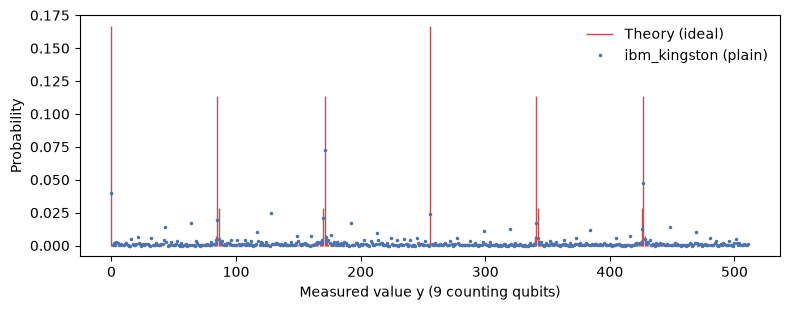

In [4]:
# Cell 7 - retrieve and analyse (re-run until job is DONE)
# Needs Cell 2 to have run in this kernel (defines analyse, theory, T, SHOTS).
import json, datetime
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from qiskit_ibm_runtime import QiskitRuntimeService
if 'analyse' not in globals():
    raise RuntimeError('Run Cell 2 first in this kernel, then re-run Cell 7.')
info = json.load(open("ibm_job_r6_v3.json"))
service = QiskitRuntimeService()
results, hists, raw = [], {}, {}

# Check status first to avoid blocking/timing out when queued
all_done = True
for label, jid in info["jobs"].items():
    job = service.job(jid)
    status = str(job.status())
    print(f"{label} {jid}: {status}")
    if "DONE" not in status.upper():
        all_done = False

if not all_done:
    print("\nJob(s) not finished yet. Please re-run this cell once status is DONE.")
else:
    for label, jid in info["jobs"].items():
        job = service.job(jid)
        d = job.result()[0].data
        cb, wb = d.c.get_bitstrings(), d.w.get_bitstrings()
        raw[label] = dict(c=cb, w=wb)
        df, hists[label] = analyse(cb, wb, f"{info['backend']} ({label})")
        results.append(df)
    out = pd.concat(results)
    out.to_csv("ibm_r6_v3_results.csv", index=False)
    json.dump(dict(info, shots=SHOTS, bitstrings=raw), open("ibm_r6_v3_bitstrings.json", "w"))
    p = theory(); ys = np.arange(2 ** T)
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.vlines(ys, 0, p, color="#C44E52", lw=1, label="Theory (ideal)")
    for (label, h), col in zip(hists.items(), ["#4C72B0", "#55A868"]):
        ax.plot(ys, h, ".", ms=3, color=col, label=f"{info['backend']} ({label})")
    ax.set_xlabel(f"Measured value y ({T} counting qubits)")
    ax.set_ylabel("Probability")
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig("ibm_r6_v3_histogram.png", dpi=200)
    from IPython.display import display
    display(out)
